<div align="center">

# 01 · Exploración y Limpieza del conjunto de datos
*Hourly Energy Consumption (PJM Interconnection)*

</div>

**Objetivo:** conocer la estructura y la calidad de los datos de las 12 regiones antes de limpiarlos.

**Entrada:** `data/raw/*.csv` (se leen con `src.data_loader`).
**Salida:**  `data/processed/` un archivo limpio por región y uno combinado + hallazgos

**Convención horaria.** `Datetime` marca el final de la hora (ver sección 1.1). La limpieza **no modifica** `Datetime`: el día operativo (`Datetime − 1 h`) se calcula después, en `src.features.agregar_variables_temporales`.

**Atípicos aislados.** Esta limpieza solo corrige valores `<= 0`. Los valores bajos aislados (`DOM` 1,253 MW y `PJMW` 487 MW) se **conservan** (decisión D2: tratamiento con el z modificado, por hacer). La sección 3.1 los lista.

## 1. Configuración y carga

`regiones` guarda un DataFrame por región (para revisar la calidad una por una) y `df` junta todas en formato largo (`Datetime`, `MW`, `region`) para comparar.

In [51]:
%load_ext autoreload
%autoreload 2

import io
from contextlib import redirect_stdout

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.config import PROCESSED_DIR
from src.data_loader import load_regions_dict, load_all_regions
from src.cleaning import (
    unificar_duplicados,
    marcar_valores_sospechosos,
    reindexar_calendario_horario,
    recortar_extremos_vacios,
    interpolar_huecos,
    validar_limpieza,
)

LIMITE_HORAS = 2   # máximo de horas seguidas que se interpolan

sns.set_theme(style="whitegrid")             # reemplaza pio.templates.default = "plotly_white"
pd.set_option("display.max_columns", None)   # evita que pandas esconda columnas con ....

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [52]:
regiones = load_regions_dict()   # {region: DataFrame}
df = load_all_regions()          # un solo DataFrame en formato largo

print(f"{len(regiones)} regiones cargadas · {len(df):,} filas en total")
df.head()

print("----------------------------------------------------------------")

df.groupby('region').size().rename('filas').to_frame()

12 regiones cargadas · 1,090,167 filas en total
----------------------------------------------------------------


,filas
region,
AEP,121273
COMED,66497
DAYTON,121275
DEOK,57739
DOM,116189
DUQ,119068
EKPC,45334
FE,62874
NI,58450


### 1.1 Estructura y convención horaria

Se verifica que `Datetime` sea de tipo fecha (`datetime64`), que `MW` sea numérico y que las series empiecen a las 01:00 y terminen a las 00:00, lo que es consistente con que `Datetime` marque el **final** de la hora.

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1090167 entries, 0 to 1090166
Data columns (total 3 columns):
 #   Column    Non-Null Count    Dtype         
---  ------    --------------    -----         
 0   Datetime  1090167 non-null  datetime64[us]
 1   MW        1090167 non-null  float64       
 2   region    1090167 non-null  str           
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 29.1 MB


In [54]:
extremos = pd.DataFrame({
    'primer_registro': {n: d['Datetime'].min() for n, d in regiones.items()},
    'ultimo_registro': {n: d['Datetime'].max() for n, d in regiones.items()},
})
extremos['hora_inicio'] = extremos['primer_registro'].dt.hour
extremos['hora_fin'] = extremos['ultimo_registro'].dt.hour
extremos

,primer_registro,ultimo_registro,hora_inicio,hora_fin
AEP,2004-10-01 01:00:00,2018-08-03,1,0
COMED,2011-01-01 01:00:00,2018-08-03,1,0
DAYTON,2004-10-01 01:00:00,2018-08-03,1,0
DEOK,2012-01-01 01:00:00,2018-08-03,1,0
DOM,2005-05-01 01:00:00,2018-08-03,1,0
DUQ,2005-01-01 01:00:00,2018-08-03,1,0
EKPC,2013-06-01 01:00:00,2018-08-03,1,0
FE,2011-06-01 01:00:00,2018-08-03,1,0
NI,2004-05-01 01:00:00,2011-01-01,1,0
PJM_Load,1998-04-01 01:00:00,2002-01-01,1,0


**Convención adoptada.** El registro de las 00:00 es el consumo de las 23:00 a las 24:00 del día anterior (la hora 24 de ese día). Por eso, en los notebooks siguientes, las variables de calendario (`fecha`, `hora`, `dia_semana`, `mes`, `es_festivo`) se calculan desde `Datetime − 1 h` (día operativo), con `src.features.agregar_variables_temporales`. Los datos limpios conservan `Datetime` tal como viene en la fuente.

## 2. Calidad de los datos

**Cobertura temporal**
La idea: si una región tiene datos desde el 1 de octubre de 2004 hasta el 3 de agosto de 2018, debería tener una fila por cada hora de ese intervalo. 

Para cada región se construye el calendario ideal (una fila por hora, sin saltos, entre su primera y última fecha) y se compara con las horas que realmente existen. Esta tabla alimenta el apartado *Calidad de los datos* de `docs/02_base_de_datos.md`.

| Campo | Qué calcula |
| :--- | :--- |
| **filas** | `len(d)`: filas del archivo |
| **nulos** | `d['MW'].isnull().sum()`: cuántos MW vienen vacíos |
| **duplicados** | `d.duplicated('Datetime').sum()`: filas extra. Marca la 2.ª aparición de cada fecha repetida, no la primera |
| **horas_faltantes** | `len(faltan)` |
| **cobertura_%** | Horas únicas dividido entre horas del calendario ideal, por 100. Responde: dentro del periodo de una región, ¿qué porcentaje de las horas existe de verdad? |
| **ceros_o_negativos** | Cuántos MW son $\le 0$ (imposibles en consumo) |

In [55]:
inicial = []
faltantes_por_region = {}

for nombre, d in regiones.items():
    # calendario ideal: una fila por hora entre la primera y la última fecha de la región
    completo = pd.date_range(d['Datetime'].min(), d['Datetime'].max(), freq='h')
    unicas = pd.DatetimeIndex(d['Datetime'].unique())
    faltan = completo.difference(unicas)
    faltantes_por_region[nombre] = faltan

    inicial.append({
        'fecha_inicial': d['Datetime'].min(),
        'fecha_final': d['Datetime'].max(),
        'region': nombre,
        'filas': len(d),
        'duplicados': int(d.duplicated('Datetime').sum()),
        'horas_faltantes': len(faltan),
        'ceros_o_negativos': int((d['MW'] <= 0).sum()),
        'nulos': int(d['MW'].isna().sum()),
        'cobertura_%': round(len(unicas) / len(completo) * 100, 2) if len(completo) > 0 else 0,
    })

inicial = pd.DataFrame(inicial).sort_values('region').set_index('region')

inicial

,fecha_inicial,fecha_final,filas,duplicados,horas_faltantes,ceros_o_negativos,nulos,cobertura_%
region,,,,,,,,
AEP,2004-10-01 01:00:00,2018-08-03,121273,4,27,0,0,99.98
COMED,2011-01-01 01:00:00,2018-08-03,66497,4,11,0,0,99.98
DAYTON,2004-10-01 01:00:00,2018-08-03,121275,4,25,0,0,99.98
DEOK,2012-01-01 01:00:00,2018-08-03,57739,4,9,0,0,99.98
DOM,2005-05-01 01:00:00,2018-08-03,116189,4,23,0,0,99.98
DUQ,2005-01-01 01:00:00,2018-08-03,119068,4,24,0,0,99.98
EKPC,2013-06-01 01:00:00,2018-08-03,45334,4,6,0,0,99.99
FE,2011-06-01 01:00:00,2018-08-03,62874,4,10,1,0,99.98
NI,2004-05-01 01:00:00,2011-01-01,58450,0,14,0,0,99.98


### 2.1 Gráfica de cobertura temporal de las 12 regiones

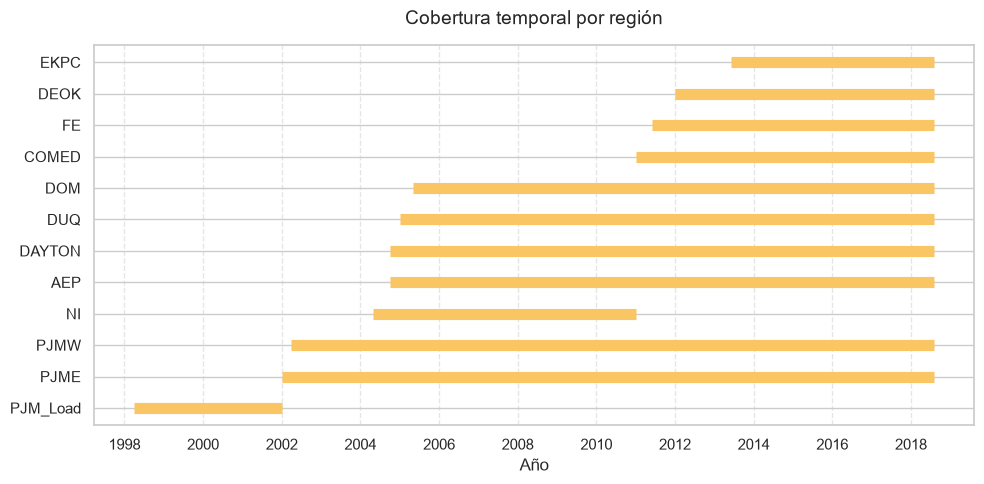

In [56]:
orden = inicial.sort_values('fecha_inicial')

fig, ax = plt.subplots(figsize=(10, 5))

ax.hlines(
    y=orden.index,
    xmin=orden['fecha_inicial'],
    xmax=orden['fecha_final'],
    linewidth=8,
    color="#FAC563",  
)

ax.set_title('Cobertura temporal por región', fontsize=14, pad=15)
ax.set_xlabel('Año')
ax.grid(True, axis='x', linestyle='--', alpha=0.5)

ax.xaxis.set_major_locator(mdates.YearLocator(2))   # una marca cada 2 años
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

**Periodo común.** Si no todas las regiones se solapan, la comparación debe hacerse por grupos. La celda calcula el periodo común de las 12 y el de las regiones que llegan hasta el final del dataset (*vigentes*).

In [57]:
inicio_comun = inicial['fecha_inicial'].max()
fin_comun = inicial['fecha_final'].min()
print(f"Periodo común a las {len(inicial)} regiones: {inicio_comun} → {fin_comun}")
print("¿Existe solape entre todas?", inicio_comun < fin_comun)

# Regiones que llegan hasta el final del dataset
corte = inicial['fecha_final'].max() - pd.Timedelta(days=7)
vigentes = inicial[inicial['fecha_final'] >= corte]
print(f"\nRegiones vigentes ({len(vigentes)}): {list(vigentes.index)}")
print(f"Periodo común de las vigentes: {vigentes['fecha_inicial'].max()} → {vigentes['fecha_final'].min()}")
print("Fuera de ese grupo:", [r for r in inicial.index if r not in vigentes.index])

Periodo común a las 12 regiones: 2013-06-01 01:00:00 → 2002-01-01 00:00:00
¿Existe solape entre todas? False

Regiones vigentes (10): ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'PJME', 'PJMW']
Periodo común de las vigentes: 2013-06-01 01:00:00 → 2018-08-03 00:00:00
Fuera de ese grupo: ['NI', 'PJM_Load']


### 2.2 Horas faltantes y duplicados

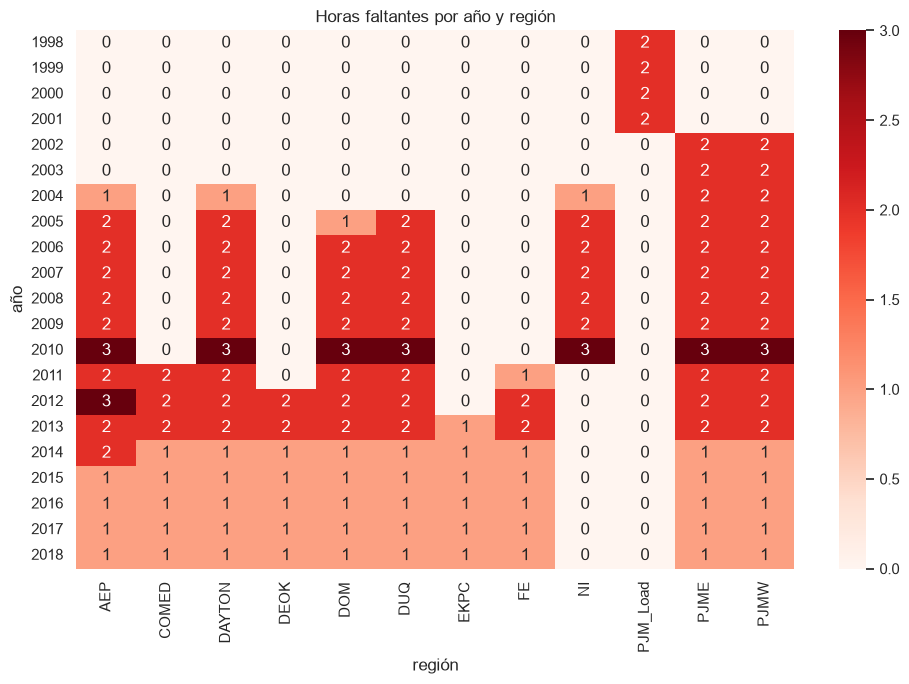

In [58]:
faltantes_anio = (
    pd.DataFrame(
        {n: pd.Series(f.year).value_counts() for n, f in faltantes_por_region.items()}
    )
    .fillna(0)
    .astype(int)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    faltantes_anio, annot=True, fmt='d', cmap='Reds', ax=ax
)

ax.set_title('Horas faltantes por año y región')
ax.set_xlabel('región')
ax.set_ylabel('año')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


**Qué muestra el gráfico**

Cada celda muestra el numero de horas que faltan en esa region ese año. La escala llega hasta 3, así que cualquier celda roja intensa son tres horas en un año de 8,760. No hay manchas grandes, es decir, no hay apagones de datos. Es la conclusión más importante: la calidad en este aspecto es muy buena.

In [59]:
# ¿En qué fechas y meses caen? (ejemplo con PJME)
f = faltantes_por_region['PJME']
print("Meses en que faltan horas:", pd.Series(f.month).value_counts().sort_index().to_dict())
list(f.strftime('%Y-%m-%d %H:%M'))

Meses en que faltan horas: {3: 12, 4: 5, 10: 5, 11: 7, 12: 1}


['2002-04-07 03:00',
 '2002-10-27 02:00',
 '2003-04-06 03:00',
 '2003-10-26 02:00',
 '2004-04-04 03:00',
 '2004-10-31 02:00',
 '2005-04-03 03:00',
 '2005-10-30 02:00',
 '2006-04-02 03:00',
 '2006-10-29 02:00',
 '2007-03-11 03:00',
 '2007-11-04 02:00',
 '2008-03-09 03:00',
 '2008-11-02 02:00',
 '2009-03-08 03:00',
 '2009-11-01 02:00',
 '2010-03-14 03:00',
 '2010-11-07 02:00',
 '2010-12-10 00:00',
 '2011-03-13 03:00',
 '2011-11-06 02:00',
 '2012-03-11 03:00',
 '2012-11-04 02:00',
 '2013-03-10 03:00',
 '2013-11-03 02:00',
 '2014-03-09 03:00',
 '2015-03-08 03:00',
 '2016-03-13 03:00',
 '2017-03-12 03:00',
 '2018-03-11 03:00']

**Causa de los huecos y duplicados.** Se comprueba si cada hora faltante o repetida coincide con un cambio de horario de EE. UU. (desde 2007: 2.º domingo de marzo y 1.er domingo de noviembre; antes: 1.er domingo de abril y último de octubre). Con `Datetime` como hora-fin, se espera que la hora que no existe en primavera sea las 03:00 y que la que se repite en otoño sea las 02:00.

In [60]:
def n_domingo(anio, mes, n):
    """n-ésimo domingo del mes (n = -1: el último)."""
    dias = pd.date_range(f'{anio}-{mes:02d}-01', periods=31, freq='D')
    dom = dias[(dias.month == mes) & (dias.dayofweek == 6)]
    return dom[n - 1] if n > 0 else dom[-1]

def cambios_de_horario(anio):
    """Regla de EE. UU.: desde 2007, marzo (2.º dom.) a noviembre (1.º dom.); antes, abril a octubre."""
    if anio >= 2007:
        return n_domingo(anio, 3, 2), n_domingo(anio, 11, 1)
    return n_domingo(anio, 4, 1), n_domingo(anio, 10, -1)

def causa(ts):
    primavera, otono = cambios_de_horario(ts.year)
    if ts.normalize() == primavera and ts.hour == 3:
        return 'primavera (03:00)'
    if ts.normalize() == otono and ts.hour == 2:
        return 'otoño (02:00)'
    return 'otra'

detalle_dups_list = []
for nombre, d in regiones.items():
    dups = d[d.duplicated('Datetime', keep='first')].copy()
    dups['region'] = nombre
    detalle_dups_list.append(dups)
detalle_dups = pd.concat(detalle_dups_list, ignore_index=True)

filas = [{'region': n, 'fecha': ts, 'tipo': 'faltante', 'causa': causa(ts)}
         for n, f in faltantes_por_region.items() for ts in f]
filas += [{'region': r.region, 'fecha': r.Datetime, 'tipo': 'repetida', 'causa': causa(r.Datetime)}
          for r in detalle_dups.itertuples()]
causas = pd.DataFrame(filas)

display(causas.groupby(['tipo', 'causa']).size().unstack(fill_value=0))
causas[causas['causa'] == 'otra']      # esperado: PJME 2010-12-10 00:00 y, quizá, alguna más

causa,otoño (02:00),otra,primavera (03:00)
tipo,,,
faltante,82,9,126
repetida,40,0,0


,region,fecha,tipo,causa
13,AEP,2010-12-10 00:00:00,faltante,otra
18,AEP,2012-12-06 04:00:00,faltante,otra
22,AEP,2014-03-11 14:00:00,faltante,otra
51,DAYTON,2010-12-10 00:00:00,faltante,otra
83,DOM,2010-12-10 00:00:00,faltante,otra
107,DUQ,2010-12-10 00:00:00,faltante,otra
148,NI,2010-12-10 00:00:00,faltante,otra
175,PJME,2010-12-10 00:00:00,faltante,otra
205,PJMW,2010-12-10 00:00:00,faltante,otra


**Lectura.** En `PJME` las faltantes de primavera caen siempre a las 03:00 del día del cambio. Hasta 2013 falta también la hora de otoño (02:00), y desde 2014 esa hora aparece duplicada, lo que explica "2 faltantes por año hasta 2013 y 1 después".

En las 12 regiones se clasifican 217 horas faltantes: **126** son la hora inexistente de primavera, **82** la de otoño y **9 no tienen relación con el cambio de horario**: el 2010-12-10 00:00 en siete regiones (`AEP`, `DAYTON`, `DOM`, `DUQ`, `NI`, `PJME` y `PJMW`), lo que sugiere una falla común de la fuente, y dos horas de `AEP` (2012-12-06 04:00 y 2014-03-11 14:00). Las 40 horas repetidas son todas de otoño (02:00).

### 2.3 Valores atípicos y sospechosos

Los valores altos en consumo eléctrico suelen ser picos reales de demanda, no errores. Por eso el conteo por rango intercuartil se separa en bajos y altos, y se revisan aparte los valores más bajos de cada región (un cero o un valor muy por debajo del promedio puede ser un error de medición).

In [61]:
df.groupby('region')['MW'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
AEP,121273.0,15500.0,2591.0,9581.0,13630.0,15310.0,17200.0,25695.0
COMED,66497.0,11420.0,2304.0,7237.0,9780.0,11152.0,12510.0,23753.0
DAYTON,121275.0,2038.0,393.0,982.0,1749.0,2009.0,2279.0,3746.0
DEOK,57739.0,3105.0,600.0,907.0,2687.0,3013.0,3449.0,5445.0
DOM,116189.0,10949.0,2414.0,1253.0,9322.0,10501.0,12378.0,21651.0
DUQ,119068.0,1659.0,302.0,1014.0,1444.0,1630.0,1819.0,3054.0
EKPC,45334.0,1464.0,379.0,514.0,1185.0,1386.0,1699.0,3490.0
FE,62874.0,7792.0,1331.0,0.0,6807.0,7700.0,8556.0,14032.0
NI,58450.0,11702.0,2371.0,7003.0,9954.0,11521.0,12897.0,23631.0


In [62]:
def contar_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({
        'bajos': int((s < q1 - 1.5 * iqr).sum()),
        'altos': int((s > q3 + 1.5 * iqr).sum()),
    })

df.groupby('region')['MW'].apply(contar_atipicos).unstack()

,bajos,altos
region,,
AEP,0,667
COMED,0,2388
DAYTON,0,1535
DEOK,34,1166
DOM,1,2105
DUQ,0,3391
EKPC,0,732
FE,1,1183
NI,0,1816


**¿Aislado o sostenido?** Un error de medición suele ser un valor aislado, muy por debajo de sus horas vecinas. Un valle real es una racha de varias horas seguidas. Para los 3 valores más bajos de cada región se calcula `MW_vs_vecinos` (el valor entre el promedio de la hora anterior y la siguiente) y `MW_vs_media_region`. Un `MW_vs_vecinos` muy por debajo de 1 (por ejemplo, menor que 0.5) indica un valor aislado y sospechoso; cercano a 1, una racha baja real.

In [63]:
filas = []
for nombre, d in regiones.items():
    d = d.sort_values('Datetime').reset_index(drop=True)
    vecinos = (d['MW'].shift(1) + d['MW'].shift(-1)) / 2
    d = d.assign(region=nombre,
                 MW_vs_media_region=d['MW'] / d['MW'].mean(),
                 MW_vs_vecinos=d['MW'] / vecinos)
    filas.append(d.nsmallest(3, 'MW'))

pd.concat(filas)[['region', 'Datetime', 'MW', 'MW_vs_media_region', 'MW_vs_vecinos']].round(2)

C:\Users\lukas\AppData\Local\Temp\ipykernel_9032\514079.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  pd.concat(filas)[['region', 'Datetime', 'MW', 'MW_vs_media_region', 'MW_vs_vecinos']].round(2)


,region,Datetime,MW,MW_vs_media_region,MW_vs_vecinos
105197,AEP,2016-10-02 05:00:00,9581.0,0.62,1.00
105198,AEP,2016-10-02 06:00:00,9604.0,0.62,0.99
105196,AEP,2016-10-02 04:00:00,9623.0,0.62,0.99
29759,COMED,2014-05-25 07:00:00,7237.0,0.63,0.98
58654,COMED,2017-09-10 06:00:00,7263.0,0.64,0.99
29760,COMED,2014-05-25 08:00:00,7269.0,0.64,0.98
34665,DAYTON,2008-09-14 18:00:00,982.0,0.48,0.94
61570,DAYTON,2011-10-11 02:00:00,1000.0,0.49,0.68
34675,DAYTON,2008-09-15 04:00:00,1011.0,0.50,0.98
55271,DEOK,2018-04-22 05:00:00,907.0,0.29,0.98


**Lectura.** `FE` (0 MW) es su primer registro y se recorta en la limpieza (`MW_vs_vecinos` queda vacío al no tener hora anterior). `DOM` (1,253 MW, 2009-12-12 00:00) y `PJMW` (487 MW, 2003-05-29 00:00) son aislados. Los valores de `PJMW` de 2012-04-01/02 (2,553 y 2,574 MW) no cumplen el criterio de aislado. `EKPC` (514 MW, 2013-09-29) es una racha de varias horas de madrugada de un domingo, es decir, un valle real y no un error. `DEOK` queda por revisar con esta tabla: sus mínimos del 2018-04-22 son consecutivos, pero el 2017-11-05 tiene dos lecturas de la misma hora de 1,044 y 2,064 MW.

## 3. Limpieza de todas las regiones

La limpieza aplica, en orden: unificar duplicados (promedio), marcar valores imposibles (`MW <= 0`), reindexar a un calendario horario completo, recortar vacíos de los extremos e interpolar huecos de hasta `LIMITE_HORAS` horas. Los mensajes de cada función se silencian y se registra una bitácora con los conteos. Si una región no pasa la validación, se anota el error y se continúa con las demás.

In [64]:
limpias = {}      # regiones que pasaron la validación
fallidas = {}     # regiones que no la pasaron (se conservan para diagnosticar)
errores = {}
bitacora = []

for nombre, d in regiones.items():
    with redirect_stdout(io.StringIO()):
        d1 = unificar_duplicados(d)
        d2 = marcar_valores_sospechosos(d1)
        d3 = reindexar_calendario_horario(d2)
        d4 = recortar_extremos_vacios(d3)
        d5 = interpolar_huecos(d4, limite_horas=LIMITE_HORAS)

    fila = {
        'region': nombre,
        'filas_originales': len(d),
        'duplicados_unificados': len(d) - len(d1),
        'valores_marcados': int(d2['MW'].isna().sum() - d1['MW'].isna().sum()),
        'horas_agregadas': len(d3) - len(d2),
        'filas_recortadas': len(d3) - len(d4),
        'huecos_interpolados': int(d4['MW'].isna().sum() - d5['MW'].isna().sum()),
        'vacios_restantes': int(d5['MW'].isna().sum()),
        'filas_finales': len(d5),
    }

    try:
        with redirect_stdout(io.StringIO()):
            validar_limpieza(d5)
        limpias[nombre] = d5
        fila['validacion'] = 'OK'
    except ValueError as e:
        fallidas[nombre] = d5
        errores[nombre] = str(e)
        fila['validacion'] = 'ERROR'

    bitacora.append(fila)

bitacora = pd.DataFrame(bitacora).set_index('region')
bitacora

,filas_originales,duplicados_unificados,valores_marcados,horas_agregadas,filas_recortadas,huecos_interpolados,vacios_restantes,filas_finales,validacion
region,,,,,,,,,
AEP,121273,4,0,27,0,27,0,121296,OK
COMED,66497,4,0,11,0,11,0,66504,OK
DAYTON,121275,4,0,25,0,25,0,121296,OK
DEOK,57739,4,0,9,0,9,0,57744,OK
DOM,116189,4,0,23,0,23,0,116208,OK
DUQ,119068,4,0,24,0,24,0,119088,OK
EKPC,45334,4,0,6,0,6,0,45336,OK
FE,62874,4,1,10,1,10,0,62879,OK
NI,58450,0,0,14,0,14,0,58464,OK


In [65]:
# Las filas finales deben cuadrar con los pasos aplicados a cada región
cuadra = bitacora['filas_finales'] == (
    bitacora['filas_originales'] - bitacora['duplicados_unificados']
    + bitacora['horas_agregadas'] - bitacora['filas_recortadas']
)
print("Cuadre de filas en todas las regiones:", bool(cuadra.all()))
print(f"Total: {bitacora['filas_originales'].sum():,} filas originales → {bitacora['filas_finales'].sum():,} finales")

# Diagnóstico: qué vacíos quedaron en las regiones que fallaron
if not errores:
    print(f"Las {len(limpias)} regiones pasaron la validación.")
for nombre, mensaje in errores.items():
    print(f"\n{nombre}: {mensaje}")
    display(fallidas[nombre][fallidas[nombre]['MW'].isna()])

Cuadre de filas en todas las regiones: True
Total: 1,090,167 filas originales → 1,090,343 finales
Las 12 regiones pasaron la validación.


### 3.1 Valores aislados que se conservan (decisión D2)

La limpieza no toca los valores bajos aislados. Se listan los que quedan muy por debajo de sus horas vecinas (`MW_vs_vecinos` es el valor entre el promedio de la hora anterior y la siguiente; menor que 0.5 es aislado), para que la decisión quede documentada y se pueda tratar después con el z modificado.

In [66]:
filas = []
for nombre, d in limpias.items():
    vecinos = (d['MW'].shift(1) + d['MW'].shift(-1)) / 2
    filas.append(d.assign(region=nombre, MW_vs_vecinos=d['MW'] / vecinos))

aislados = pd.concat(filas)
aislados[aislados['MW_vs_vecinos'] < 0.5][['region', 'Datetime', 'MW', 'MW_vs_vecinos']].round(2)

C:\Users\lukas\AppData\Local\Temp\ipykernel_9032\2059378777.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  aislados[aislados['MW_vs_vecinos'] < 0.5][['region', 'Datetime', 'MW', 'MW_vs_vecinos']].round(2)


,region,Datetime,MW,MW_vs_vecinos
40463,DOM,2009-12-12,1253.0,0.1
10151,PJMW,2003-05-29,487.0,0.1


## 4. Guardado y verificación

- Un archivo limpio por región: `<REGION>_clean.parquet`.
- Un archivo combinado en formato largo: `consumo_horario.parquet` (`Datetime`, `MW`, `region`).

Solo se guardan las regiones que pasaron la validación. Los datos conservan los MW reales (no se normalizan). Después se leen de nuevo desde disco y se validan: `validar_limpieza` lanza un error si algún archivo no cumple.

In [67]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

for nombre, d in limpias.items():
    d.to_parquet(PROCESSED_DIR / f"{nombre}_clean.parquet", index=False)

limpio = (
    pd.concat([d.assign(region=nombre) for nombre, d in limpias.items()], ignore_index=True)
    .sort_values(['region', 'Datetime'])
    .reset_index(drop=True)
)
limpio.to_parquet(PROCESSED_DIR / "consumo_horario.parquet", index=False)

print(f"{len(limpias)} archivos por región + consumo_horario.parquet ({len(limpio):,} filas)")
if errores:
    print("Sin guardar (no pasaron la validación):", list(errores))

12 archivos por región + consumo_horario.parquet (1,090,343 filas)


In [68]:
archivos = sorted(PROCESSED_DIR.glob("*_clean.parquet"))

verificacion = []
for ruta in archivos:
    d = pd.read_parquet(ruta)
    with redirect_stdout(io.StringIO()):
        validar_limpieza(d)
    verificacion.append({
        'archivo': ruta.name,
        'filas': len(d),
        'inicio': d['Datetime'].min(),
        'fin': d['Datetime'].max(),
        'vacios': int(d['MW'].isna().sum()),
    })

display(pd.DataFrame(verificacion).set_index('archivo'))

leido = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
print(leido.dtypes)
assert len(leido) == 1_090_343, f"Se esperaban 1,090,343 filas y hay {len(leido):,}"
leido.groupby('region').size().rename('filas').to_frame()

,filas,inicio,fin,vacios
archivo,,,,
AEP_clean.parquet,121296,2004-10-01 01:00:00,2018-08-03,0
COMED_clean.parquet,66504,2011-01-01 01:00:00,2018-08-03,0
DAYTON_clean.parquet,121296,2004-10-01 01:00:00,2018-08-03,0
DEOK_clean.parquet,57744,2012-01-01 01:00:00,2018-08-03,0
DOM_clean.parquet,116208,2005-05-01 01:00:00,2018-08-03,0
DUQ_clean.parquet,119088,2005-01-01 01:00:00,2018-08-03,0
EKPC_clean.parquet,45336,2013-06-01 01:00:00,2018-08-03,0
FE_clean.parquet,62879,2011-06-01 02:00:00,2018-08-03,0
NI_clean.parquet,58464,2004-05-01 01:00:00,2011-01-01,0


Datetime    datetime64[us]
MW                 float64
region                 str
dtype: object


,filas
region,
AEP,121296
COMED,66504
DAYTON,121296
DEOK,57744
DOM,116208
DUQ,119088
EKPC,45336
FE,62879
NI,58464


## 5. Hallazgos y decisiones

| Tema | Hallazgo |
|---|---|
| Estructura | 12 regiones y 1,090,167 filas. `Datetime` es `datetime64` y `MW` es `float64`. Sin nulos en ninguna región. |
| Convención horaria | `Datetime` marca el **final** de la hora (hora del este de EE. UU. con cambio de horario). El registro de las 00:00 es la hora 24 del día anterior, así que el calendario se calcula desde `Datetime − 1 h` (día operativo). |
| Periodo común | **No existe un periodo común a las 12 regiones.** `PJM_Load` cubre 1998-04 → 2002-01 y `NI` 2004-05 → 2011-01. Las otras 10 comparten 2013-06-01 → 2018-08-03 (días operativos hasta el 2018-08-02). |
| Cobertura | Entre 99.98 % y 99.99 % en todas las regiones. |
| Duplicados | 4 fechas repetidas (2014-11-02, 2015-11-01, 2016-11-06 y 2017-11-05) a las 02:00 en 10 regiones (no en `NI` ni `PJM_Load`), con valores distintos. Son el primer domingo de noviembre: cambio de horario de otoño. |
| Horas faltantes | 217 en total (entre 6 y 30 por región): 126 de primavera (03:00), 82 de otoño (02:00, hasta 2013; desde 2014 aparece duplicada) y **9 sin causa horaria** (2010-12-10 00:00 en 7 regiones y 2 de `AEP`). |
| Valores sospechosos | `FE` 0 MW es su primer registro (se recorta). Aislados: `DOM` 1,253 MW (2009-12-12) y `PJMW` 487 MW (2003-05-29), que se conservan y quedan para el z modificado (D2). Los de `PJMW` de 2012-04-01/02 no cumplen el criterio de aislado. `EKPC` (514 MW) es una racha baja real. `DEOK` queda por revisar. |
| Atípicos (IQR) | Altos: de 567 (`PJM_Load`) a 3,450 (`PJME`) por región, picos reales que se conservan. Bajos: 34 en `DEOK`, 10 en `PJMW`, 5 en `PJME` (2012-10-30, huracán Sandy), 1 en `DOM`, 1 en `FE` y 0 en el resto. |
| Limpieza | 40 duplicados unificados, 217 horas interpoladas (0.02 %) y 1 fila recortada (el 0 inicial de `FE`). Las 12 regiones pasan `validar_limpieza` y quedan **1,090,343 filas**. |
| Escala | Las magnitudes difieren mucho (`PJME` ≈ 32,080 MW de media frente a `DUQ` ≈ 1,659 MW). Para comparar formas hay que normalizar. |

### Decisiones aplicadas

| Problema | Decisión |
|---|---|
| Horas repetidas (cambio de horario de otoño, desde 2014) | Promediar las lecturas |
| Horas ausentes (primavera a las 03:00 y, hasta 2013, otoño a las 02:00) | Reindexar a un calendario horario completo y estimarlas |
| Valores `<= 0` | Marcarlos como vacío. Si no están en los extremos, se estiman |
| Vacíos en el primer o último registro (por ejemplo, el 0 MW inicial de `FE`) | Recortarlos (no hay dato para estimarlos) |
| Vacíos cortos | Interpolación lineal hasta `LIMITE_HORAS = 2` |
| Vacíos largos | No se rellenan; la validación los reporta |
| Picos altos de demanda | Se conservan (consumo real) |
| Valores bajos aislados (`DOM`, `PJMW`) | Se conservan; tratamiento con z modificado por hacer (D2) |
| Rachas bajas reales (`EKPC` 514 MW) | Se conservan (no son errores) |
| Convención horaria | `Datetime` no se modifica (hora-fin); el día operativo se calcula en `features.py` |

**Limitaciones:** las horas que no existieron en la hora local de primavera, y las de otoño anteriores a 2014, se rellenan por interpolación; desde 2014 las dos lecturas de otoño se promedian; solo se corrigen valores `<= 0`. Las series `NI` y `COMED` se guardan por separado (decisión D3, por confirmar).